# Milestone 2: analyze the saved customer experiment

**After the World Cup brings in free-trial customers, which action improves paid retention enough to be worth its cost?**

Notebook 1 created fictional customers and saved them. This notebook loads that same file and compares the three groups. We keep **every assigned customer**, even those who never paid or later canceled. We will describe uncertainty rather than declare the highest average a winner. This is simulated evidence, not a finding about real customer behavior.


## 1. How do I start after Notebook 1?


Run Notebook 1 to create the data, then Notebook 2 to analyze it. Run each notebook from top to bottom.

Locally, install `requirements.txt` from the repository root and start Jupyter Lab (see the README). In Colab, clone this branch once, change to the repository folder, and install the requirements. Use the **same checkout and data folder** for both notebooks. If you use separate Colab runtimes, copy the generated `data/` files into the second checkout, or rerun Notebook 1 there before Notebook 2. Uploading a notebook alone does not include the Python helpers.

The next cell imports the libraries used below. Imports make their functions available; they do not generate or analyze data yet.


In [1]:
from pathlib import Path
import sys
import json
import hashlib
import pandas as pd
from IPython.display import display


The next cell locates the project and imports file readers, the existing comparison calculations, and small display helpers. Display helpers format tables and charts; they do not change the statistical calculations.


In [2]:
ROOT = Path.cwd()
if not (ROOT / 'retention').is_dir():
    ROOT = ROOT.parent  # Jupyter may start inside notebooks/.
if not (ROOT / 'retention').is_dir():
    raise FileNotFoundError('Open Jupyter from the repository root or notebooks/ folder.')
sys.path.insert(0, str(ROOT))

from retention.simulation import ARMS, PRE_OFFER_FEATURES
from retention.analysis import compare_binary, compare_revenue
from retention.data import load_customers, load_oracle
from retention.reporting import OFFER_NAMES, comparison_table, plot_comparison, oracle_comparison


## 2. Which saved data will we analyze?

We load `data/generated/customers.csv`, created by Notebook 1. We **do not generate another experiment**. If it is missing, the next cell tells you to run Notebook 1 first. The answer key is not loaded yet.

Before viewing results, keep our existing plan: compare each offer with no special offer. Our main outcome is paid retention 90 days after scheduled trial end, with two comparisons. Conversion and two revenue measures are supporting outcomes, with six comparisons. We account for making several comparisons, and use a 5% false-alarm threshold separately for those two sets. Details are in the optional appendix. We do not choose a different outcome or test after seeing which result looks favorable.

The next cell reads the customer CSV and displays its size and first three assignments. All later averages use the entire file, not only converters.


In [3]:
CUSTOMER_FILE = ROOT / 'data' / 'generated' / 'customers.csv'
customers = load_customers(CUSTOMER_FILE)
print(f'Loaded {len(customers):,} customers saved by Notebook 1.')
display(customers[['customer_id', 'assigned_offer', 'retained_day90']].head(3))


Loaded 12,000 customers saved by Notebook 1.


,customer_id,assigned_offer,retained_day90
0,customer_0000001,discount_20pct,False
1,customer_0000002,discount_20pct,False
2,customer_0000003,content_recommendation,False


The next cell checks the saved dates and eligibility without reading the answer key. `assert` stops execution if a rule fails, so we do not silently continue with incomplete or mismatched data.


In [4]:
assert customers.customer_id.is_unique
assert customers.eligible_at_offer.all() and customers.active_at_offer.all()
assert not customers.canceled_before_offer.any()
assert customers.active_days_last3_pre.ge(1).all()
assert customers.feature_window_end_date.eq(customers.assignment_date).all()
assert (customers.scheduled_trial_end_date - customers.assignment_date).dt.days.eq(1).all()
assert (customers.followup_end_date - customers.scheduled_trial_end_date).dt.days.eq(90).all()
assert customers.assignment_probability.eq(1 / 3).all()
assert (~customers.retained_day90 | customers.converted).all()
assert not any(column.startswith(('p_', 'effect_')) for column in customers)


## 3. What happened in the three groups?

The next cell calculates a result for each group: how many customers were assigned, how many still paid at day 90, how many converted, and average revenue. This shows the group results before we explain their differences.


In [5]:
summary = customers.groupby('assigned_offer').agg(
    assigned_customers=('customer_id', 'size'),
    retained_customers=('retained_day90', 'sum'),
    retention_percent=('retained_day90', 'mean'),
    conversion_percent=('converted', 'mean'),
    subscription_revenue=('subscription_revenue_90', 'mean'),
    revenue_less_delivery=('revenue_less_delivery_cost_90', 'mean'),
).reindex(ARMS)
summary[['retention_percent', 'conversion_percent']] *= 100
assert summary.assigned_customers.sum() == len(customers)
display(summary.rename(index=OFFER_NAMES).round(2))


,assigned_customers,retained_customers,retention_percent,conversion_percent,subscription_revenue,revenue_less_delivery
assigned_offer,,,,,,
No special offer,3999,706,17.65,35.88,11.58,11.58
Content recommendation,3970,714,17.98,35.72,11.79,11.69
20% discount,4031,619,15.36,31.08,9.23,9.23


Read one row at a time. `retention_percent` is the percentage of **all customers assigned to that group** who still paid 90 days after scheduled trial end. `conversion_percent` is the percentage who started paying by trial end. Revenue columns are dollars **per assigned customer**, including zero-revenue nonconverters.

For example, 17% retention means about 17 of every 100 assigned customers still pay. It does not mean 17% of converters. A higher sample average can arise by chance; we will add uncertainty ranges before drawing conclusions.

The next cell shows one customer behind those averages. `True` means yes. The full analysis still includes every customer, not just this example.


In [6]:
person = customers.iloc[0]
print(f"Example: {person.customer_id} received {OFFER_NAMES[person.assigned_offer]}.")
print(f"Started paying: {person.converted}; still paying at day 90: {person.retained_day90}.")
print(f"Their subscription revenue after discounts was ${person.subscription_revenue_90:.2f}.")
print('This row contributes to its assigned group even if the customer did not convert.')


Example: customer_0000001 received 20% discount.
Started paying: False; still paying at day 90: False.
Their subscription revenue after discounts was $0.00.
This row contributes to its assigned group even if the customer did not convert.


## 4. Did the groups start with similar customers?

Each customer had a one-in-three chance of each offer. The next cell shows group sizes and average **pre-offer** behavior. All features were recorded before the offer could change behavior.


In [7]:
counts = customers.assigned_offer.value_counts().reindex(ARMS)
display(counts.rename(index=OFFER_NAMES).to_frame('Assigned customers'))
feature_means = customers.groupby('assigned_offer')[list(PRE_OFFER_FEATURES)].mean()
display(feature_means.reindex(ARMS).rename(index=OFFER_NAMES).round(2))


,Assigned customers
assigned_offer,
No special offer,3999
Content recommendation,3970
20% discount,4031


,active_days_pre,active_days_last3_pre,watch_hours_pre,world_cup_share_pre,non_world_cup_hours_pre,content_breadth_pre,pricing_page_visits_pre,discovery_sessions_pre
assigned_offer,,,,,,,,
No special offer,7.06,2.01,9.26,0.59,3.77,2.62,1.54,2.88
Content recommendation,7.00,2.01,8.96,0.60,3.59,2.62,1.57,2.82
20% discount,6.99,2.02,9.08,0.60,3.66,2.63,1.56,2.83


Small starting differences are expected with random assignment. These tables help us notice obvious problems, but cannot prove assignment was random. We do not remove customers, redraw offers, or test lots of subgroups to get a preferred result. The next cell shows the spread of behavior within each group: a standard deviation describes how much individual values vary around the group average.


In [8]:
feature_spread = customers.groupby('assigned_offer')[list(PRE_OFFER_FEATURES)].std()
display(feature_spread.reindex(ARMS).rename(index=OFFER_NAMES).round(2))


,active_days_pre,active_days_last3_pre,watch_hours_pre,world_cup_share_pre,non_world_cup_hours_pre,content_breadth_pre,pricing_page_visits_pre,discovery_sessions_pre
assigned_offer,,,,,,,,
No special offer,2.46,0.75,7.52,0.2,3.94,1.21,1.34,2.14
Content recommendation,2.48,0.74,7.35,0.2,3.69,1.20,1.34,2.09
20% discount,2.48,0.74,7.57,0.2,3.90,1.20,1.38,2.16


## 5. How much did each offer change paid retention?

We subtract the no-special-offer retention rate from each offer's rate. A change from 17% to 19% is **+2 percentage points**, not a 2% relative increase.

The next cell uses the existing statistical helper to calculate those differences, uncertainty ranges, and test results. It adjusts for our two planned comparisons so testing both offers does not give us two unchecked chances to make a false-positive claim. The table keeps all assigned customers in each denominator.


In [9]:
primary = compare_binary(customers, 'retained_day90', family_size=2)
display(comparison_table(primary, percentage_points=True))


,Offer,Control customers,Offer customers,Difference (pp),Range low (pp),Range high (pp),Adjusted p-value
0,Content recommendation,3999,3970,0.330,-1.591,2.252,1
1,20% discount,3999,4031,-2.298,-4.155,-0.442,0.01106


Positive differences favor the offer; negative differences favor no special offer. The “Range low” and “Range high” columns are adjusted confidence limits: they show the uncertainty around the estimate. If a range crosses zero, the data leave both a gain and a loss plausible. That does not prove the offer has no effect.

The adjusted p-value measures how surprising the difference would be if the groups had equal retention probabilities, after allowing for both comparisons. A value below 0.05 counts as evidence of a difference under our plan. It is **not** the probability an offer works, and it does not measure whether a difference is worth its cost. The interval method is designed to cover the true effects in at least roughly 95% of repeated experiments across this pair of comparisons, not to assign a probability to this particular fixed effect.

The next cell plots the same adjusted ranges. The vertical line at zero represents no change. It does not run another test.


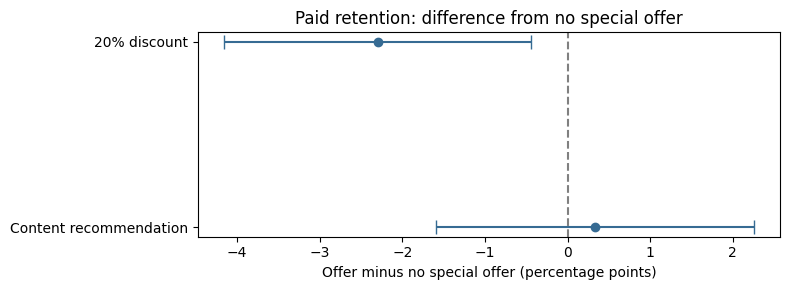

In [10]:
plot_comparison(primary, 'Paid retention: difference from no special offer',
                percentage_points=True)


The next cell translates the tests into a short statement for this run. It does not rank offers by their sample averages or claim that one offer beats the other.


In [11]:
for result in primary.itertuples():
    name = OFFER_NAMES[result.offer]
    if result.p_adjusted >= .05:
        print(f'{name}: not enough evidence to distinguish its retention effect from zero.')
    elif result.estimate > 0:
        print(f'{name}: evidence of higher average retention in this simulated run.')
    else:
        print(f'{name}: evidence of lower average retention in this simulated run.')
print('These results do not establish a deployment winner.')


Content recommendation: not enough evidence to distinguish its retention effect from zero.
20% discount: evidence of lower average retention in this simulated run.
These results do not establish a deployment winner.


## 6. Did either offer change conversion by trial end?

Conversion is a supporting outcome; our main success measure remains day-90 retention. The next cell compares conversion rates using all assigned customers. We adjust this and the upcoming revenue tests as **six supporting comparisons together**, rather than searching them for a favorable result.


In [12]:
conversion = compare_binary(customers, 'converted', family_size=6)
display(comparison_table(conversion, percentage_points=True))


,Offer,Control customers,Offer customers,Difference (pp),Range low (pp),Range high (pp),Adjusted p-value
0,Content recommendation,3999,3970,-0.166,-3.000,2.668,1
1,20% discount,3999,4031,-4.800,-7.575,-2.024,3.11e-05


Read this table like the retention table: the difference is in percentage points and the adjusted range shows uncertainty. More people starting to pay does not necessarily mean more stay or that enough revenue remains after offer costs. A supporting result does not replace the main retention result.


## 7. Did enough subscription revenue remain after offer costs?

The next cell compares average subscription revenue and then revenue after subtracting offer delivery costs. The amounts are dollars per **assigned** customer, including nonconverters.

`subscription_revenue_90` already subtracts the first-month discount. `revenue_less_delivery_cost_90` also subtracts $0.10 for every content recommendation assignment. Nonconverters can therefore contribute −$0.10 to the second measure. We must not subtract the discount again.

Neither measure is profit: acquisition, licensing, baseline hosting, taxes, and other operating costs are missing.


In [13]:
subscription = compare_revenue(customers, 'subscription_revenue_90', family_size=6)
after_delivery = compare_revenue(customers, 'revenue_less_delivery_cost_90', family_size=6)
print('Subscription revenue after discounts:')
display(comparison_table(subscription))
print('Subscription revenue after discounts and delivery costs:')
display(comparison_table(after_delivery))


Subscription revenue after discounts:


,Offer,Control customers,Offer customers,Difference (USD per customer),Range low (USD per customer),Range high (USD per customer),Adjusted p-value
0,Content recommendation,3999,3970,0.206,-0.868,1.280,1
1,20% discount,3999,4031,-2.351,-3.358,-1.344,4.527e-09


Subscription revenue after discounts and delivery costs:


,Offer,Control customers,Offer customers,Difference (USD per customer),Range low (USD per customer),Range high (USD per customer),Adjusted p-value
0,Content recommendation,3999,3970,0.106,-0.968,1.180,1
1,20% discount,3999,4031,-2.351,-3.358,-1.344,4.527e-09


A positive dollar difference favors the offer on that revenue measure. A range crossing zero leaves gains and losses plausible. The two tables are closely related, not independent confirmations. All six supporting comparisons share one adjustment, separate from the two main retention comparisons. The next cell draws their adjusted ranges.


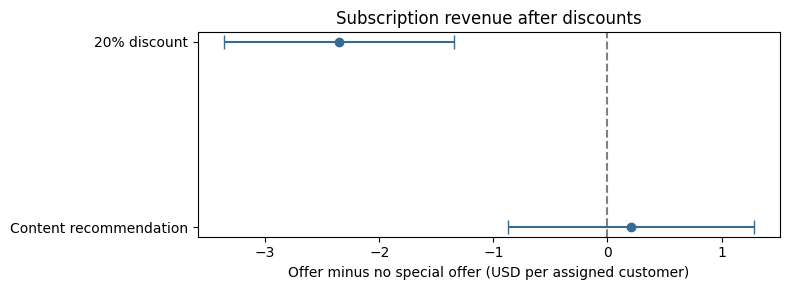

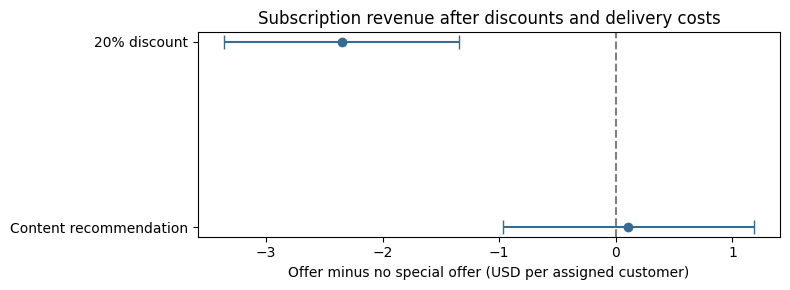

In [14]:
plot_comparison(subscription, 'Subscription revenue after discounts')
plot_comparison(after_delivery, 'Subscription revenue after discounts and delivery costs')


## 8. What can we conclude, and where do we save the results?

Consider the retention and revenue ranges together. An offer with a slightly higher average but a wide range is still uncertain. A small p-value does not make an effect important enough to deploy. We have not set a minimum worthwhile retention gain, accounted for all operating costs, or tested real customers. We cannot claim profitability or choose a real-world winner from this simulation.

No customer targeting, ML, or dbt is built. These comparisons describe average effects across eligible customers, not who should receive an offer.

The next cell saves full-precision results under `data/milestone2/`. Displayed tables are rounded for readability; the saved results retain the existing statistics, including the ordinary and adjusted intervals. It does not copy or replace the input customer data.


In [15]:
RESULTS_DIR = ROOT / 'data' / 'milestone2'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
revenue = pd.concat([subscription, after_delivery], ignore_index=True)
primary.to_csv(RESULTS_DIR / 'primary_retention_comparisons.csv', index=False)
conversion.to_csv(RESULTS_DIR / 'secondary_conversion_comparisons.csv', index=False)
revenue.to_csv(RESULTS_DIR / 'secondary_revenue_comparisons.csv', index=False)
print('Saved analysis tables under ignored data/milestone2/.')


Saved analysis tables under ignored data/milestone2/.


The next cell records the input file and its fingerprint—a value that changes if the file contents change—so we can tell which saved data produced these results.


In [16]:
run_info = {
    'input_file': 'data/generated/customers.csv', 'customers': len(customers),
    'input_sha256': hashlib.sha256(CUSTOMER_FILE.read_bytes()).hexdigest(),
    'primary_alpha': .05, 'primary_family_size': 2, 'secondary_family_size': 6,
}
(RESULTS_DIR / 'analysis_run_metadata.json').write_text(json.dumps(run_info, indent=2) + '\n')


242

## 9. Final simulation check: how close are our estimates to the planted effects?

Only now do we load `data/evaluation_only/oracle_probabilities.csv`, the separate answer key saved by Notebook 1. If it is missing, the code tells you to run Notebook 1 first. Everything above used observed data without that key.

The answer key contains each customer's invented outcome probabilities under all three offers. These values are simulation ground truth for checking methods, **not features a real model could know**. We never add them to customer features or use them to select a favorable test.

The next cell loads the key and checks that it matches the saved customer cohort and design.


In [17]:
ORACLE_FILE = ROOT / 'data' / 'evaluation_only' / 'oracle_probabilities.csv'
oracle_check = load_oracle(ORACLE_FILE)
from retention.simulation import validate_experiment
validate_experiment(customers, oracle_check)


The next cell averages each offer’s probabilities over the **same entire customer cohort**, including nonconverters, and compares the planted offer-minus-control difference with our estimate. The helper keeps this check separate from observed-data analysis. Retention uses the probability of being retained, not retention conditional on conversion.


In [18]:
retention_check = oracle_comparison(primary, oracle_check, 'p_retained_day90')
conversion_check = oracle_comparison(conversion, oracle_check, 'p_conversion')
diagnostic = pd.concat([retention_check, conversion_check], ignore_index=True)
display(diagnostic.round(3))
diagnostic.to_csv(RESULTS_DIR / 'oracle_estimate_diagnostic.csv', index=False)
del oracle_check


,outcome,offer,observed_effect_pp,adjusted_ci_low_pp,adjusted_ci_high_pp,planted_cohort_effect_pp,observed_minus_planted_pp,planted_inside_adjusted_interval
0,retained_day90,content_recommendation,0.330,-1.591,2.252,1.747,-1.416,True
1,retained_day90,discount_20pct,-2.298,-4.155,-0.442,-1.863,-0.436,True
2,converted,content_recommendation,-0.166,-3.000,2.668,1.350,-1.516,True
3,converted,discount_20pct,-4.800,-7.575,-2.024,-3.073,-1.727,True


The planted effect is what the simulator expects; the observed effect is what happened in this one run. They differ because customers were randomly assigned and outcomes were sampled. One range containing the key does not prove the method always covers the truth, and one miss would not automatically mean a bug. Repeated simulated experiments would be needed to assess that. The key does not directly give expected revenue, so this check covers retention and conversion only.

All rows and probabilities are invented. These results are not evidence about real customer behavior.


## Optional appendix: how are the tests and uncertainty ranges calculated?

You can follow the main tables without reading this section. The methods are unchanged from the previous analysis.

* **Two-proportion z test:** compares the fraction retained (or converted) in two independent groups. It tests both possible directions, not only gains. **Wald interval** is the name of the large-sample uncertainty range for their difference. It combines each group's estimated variation. The helper requires at least 10 successes and 10 failures per group; tiny or rare-outcome samples need another method.
* **Welch t test and interval:** compares average dollars while allowing the groups to have different variability. Thousands of independent customers support an approximate analysis of averages despite many zero-revenue rows. It retains zero and negative values. Small samples, extreme revenue outliers, missing data, or linked households would need more care.
* **Bonferroni adjustment:** protects against false alarms when making several comparisons. The two main tests multiply raw p-values by 2 (capped at 1) and use 97.5% individual intervals. Together they have at least approximately 95% coverage. The six supporting tests multiply by 6 and use 99.1667% individual intervals, with the same approximate group coverage. The two sets are separate; there is no single 5% guarantee over all eight tests.
* A **p-value** is computed assuming no average difference. It is not the probability that assumption is true. “Not enough evidence” does not prove zero effect or equivalence. The proportion test uses a shared rate to calculate its test variance, while the interval uses each group's own rate, so borderline decisions can differ slightly.

For retention, the difference is `offer rate − control rate`. Its standard error is `sqrt(p_offer × (1−p_offer)/n_offer + p_control × (1−p_control)/n_control)`. The adjusted interval widens this by the planned number of comparisons. Revenue uses the corresponding unequal-variance calculation in `retention/analysis.py`. See [`docs/experiment_analysis.md`](../docs/experiment_analysis.md) for full details.

Run `python -m pytest -q` to check the simulator, calculations, and CSV handoff. This milestone ends here; ML targeting, uplift modeling, and dbt remain later work.
